 # Exercise 1 - Solution
## Support vector machines.
Perception is an important step for autonomous systems. We will look into one method of classifying data given a dataset containing inputs and corresponding targets. In this case we will look at the [Iris dataset](https://en.wikipedia.org/wiki/Iris_flower_data_set), but it could just as well have been a point cloud or images of people or dogs and cats.

Today we will work with classification using [support vector machines](https://en.wikipedia.org/wiki/Support-vector_machine).
We will use the built in function from sklearn. 

In [28]:
import numpy as np
import sklearn as sk
from sklearn import datasets, svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

try:
    import pandas as pd
except ImportError:
    !pip install pandas
    import pandas as pd

%matplotlib inline

# Helper function for visualising a 2D decision boundary.
# Why a meshgrid: an SVM's decision boundary is not a simple parametric curve —
# it depends on the support vectors and kernel in a way that has no closed-form
# equation to plot directly. Instead we sample the feature space at a fine
# resolution (step h=0.02) using a grid, classify every grid point, and colour
# each region by its predicted class. This "brute-force" approach works for any
# classifier regardless of its internal structure.
# Why only 2D: SVMs can be trained on arbitrarily many features, but a decision
# boundary can only be drawn in the same space as the input. For 3D or 4D data
# there is no straightforward 2D boundary to render; a 3D scatter coloured by
# predicted class is used instead (see Exercises 2 and 3).
def plot_fit(X, y, clf):
    """
    X = samples (must be 2D)
    y = ground truth labels
    clf = trained classifier with a .predict() method
    """
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    fig = plt.figure(1, figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)  # Coloured decision regions
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='black')  # True labels as dots
    plt.xlabel('Sepal length')
    plt.ylabel('Sepal width')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.xticks(())
    plt.yticks(())

In [29]:
# Load the Iris dataset — a classic multiclass classification benchmark.
# The dataset contains 150 samples from three species of Iris (setosa,
# versicolor, virginica), each described by four measurements (features):
#   0: sepal length (cm)
#   1: sepal width  (cm)
#   2: petal length (cm)
#   3: petal width  (cm)
# Why start with only two features: using just sepal length and width keeps the
# problem 2D so we can directly visualise the decision boundary in the feature
# space using plot_fit. With more features the data is no longer plottable in
# 2D without dimensionality reduction (see Exercise 2 and Exercise 2 notebook).
# This intentionally limited starting point lets us build intuition before
# adding more dimensions in the later exercises.
iris = sk.datasets.load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df)

X = iris_df.iloc[:, :2]  # Use only the first two features (sepal length, sepal width)
display(X)
y = iris.target           # Integer class labels: 0=setosa, 1=versicolor, 2=virginica
print("Number of data points ::", X.shape[0])
print("Number of features    ::", X.shape[1])

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


Number of data points :: 150
Number of features    :: 2


## Pandas
We will use pandas to manage our data.
Initially we will only use the two first data points, i.e. the sepal length and sepal width.

We plot the data and we can see all our samples

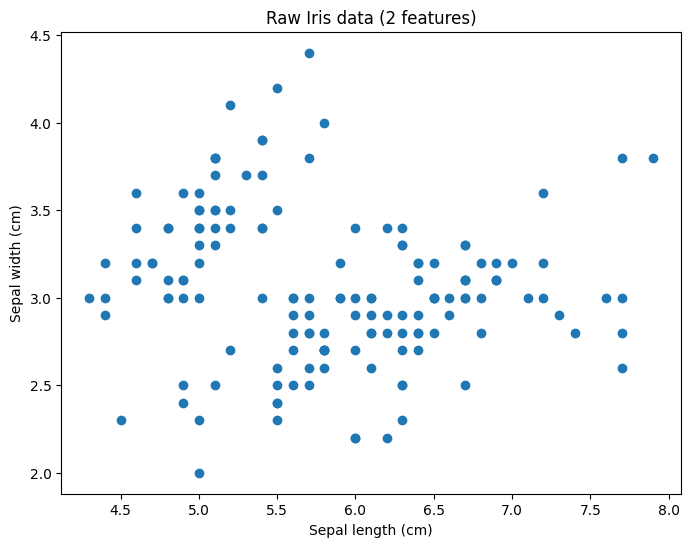

In [30]:
# Plot the raw 2D data to understand the separability problem before any training.
# Notice that the three classes overlap significantly in the sepal length/width
# space — particularly versicolor and virginica. This gives early evidence that a
# purely linear boundary will struggle and motivates trying non-linear kernels later.
fig1 = plt.figure(1, figsize=(8, 6))
ax = plt.scatter(X['sepal length (cm)'], X['sepal width (cm)'])
plt.xlabel('Sepal length (cm)')
plt.ylabel('Sepal width (cm)')
plt.title('Raw Iris data (2 features)')
plt.show()

## Normalization
Using sklearns preprocessing we can normalize the data to have zero mean and 1 variance.

```python
X_scaled = StandardScaler().fit_transform(X)
```
Plot the data — did you succeed with normalizing the data?

Mean before scaling: [5.84333333 3.05733333]
Std  before scaling: [0.82530129 0.43441097]
Mean after  scaling: [-0. -0.]
Std  after  scaling: [1. 1.]


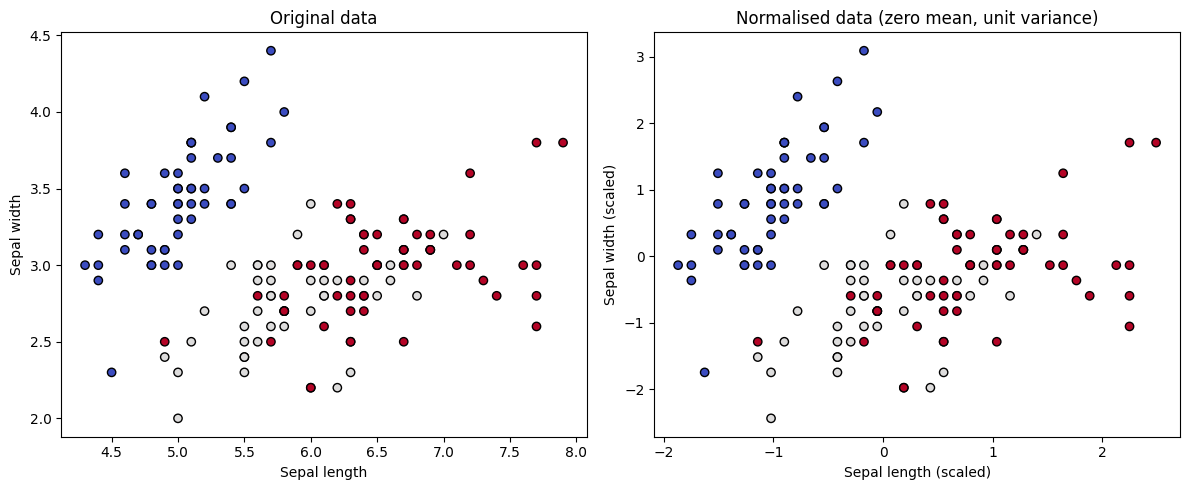

In [31]:
# Normalise the features to zero mean and unit variance before feeding them to the SVM.
# Why normalisation matters for SVMs: an SVM finds a hyperplane that maximises the
# margin between classes. The margin is measured in the feature space using Euclidean
# distance. If features are on very different scales — e.g. sepal length ~5–8 cm
# while another feature might be measured in millimetres — then the distance metric
# is dominated by the large-scale feature and the SVM effectively ignores the others.
# StandardScaler removes this bias: after scaling, each feature contributes equally
# to distances, and the SVM can find the true maximum-margin boundary.
# Why zero mean and unit variance specifically: centring to zero mean ensures the
# data is symmetric around the origin, which helps the optimiser converge faster.
# Scaling to unit variance (std=1) makes all features commensurable. The result is
# confirmed by printing the means and stds before and after.
X_scaled = StandardScaler().fit_transform(X)

print("Mean before scaling:", np.mean(X, axis=0).values)
print("Std  before scaling:", np.std(X, axis=0).values)
print("Mean after  scaling:", np.mean(X_scaled, axis=0).round(6))  # Should be ~0
print("Std  after  scaling:", np.std(X_scaled, axis=0).round(6))   # Should be ~1

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='black')
axes[0].set_title('Original data')
axes[0].set_xlabel('Sepal length')
axes[0].set_ylabel('Sepal width')

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='black')
axes[1].set_title('Normalised data (zero mean, unit variance)')
axes[1].set_xlabel('Sepal length (scaled)')
axes[1].set_ylabel('Sepal width (scaled)')

# The shape of the point cloud is identical — scaling is a linear transform that
# preserves relative distances within each feature. The class overlap looks the same,
# but the axes now show standardised units instead of centimetres.
plt.tight_layout()
plt.show()

### Training / testing split
We now create a training and testing set.
The training set is to train our model and the testing set is to make sure we don't overfit to the data.

In [32]:
# Split the data into a training set and a held-out test set.
# Why hold out a test set: a model that has seen its training data during
# fitting can memorise it perfectly ("overfitting") and report 100% accuracy
# without having learned anything generalisable. The test set is never shown
# to the model during training, so its accuracy is an honest estimate of how
# well the model will perform on new, unseen samples.
# Why 20% test / 80% train: a common default that balances having enough data
# to train a representative model (80 samples per class here is generous for SVM)
# against having enough hold-out samples to get a reliable accuracy estimate.
# Why random_state=42: fixing the random seed makes the split reproducible —
# re-running the notebook always produces the same split, so accuracy numbers
# are comparable across runs and across different kernel experiments below.
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing  samples: {X_test.shape[0]}")

Training samples: 120
Testing  samples: 30


## Train and test the accuracy of your model
Using sklearns `LinearSVC` to train a linear support vector classifier.

Training accuracy: 0.767
Testing  accuracy: 0.933


/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


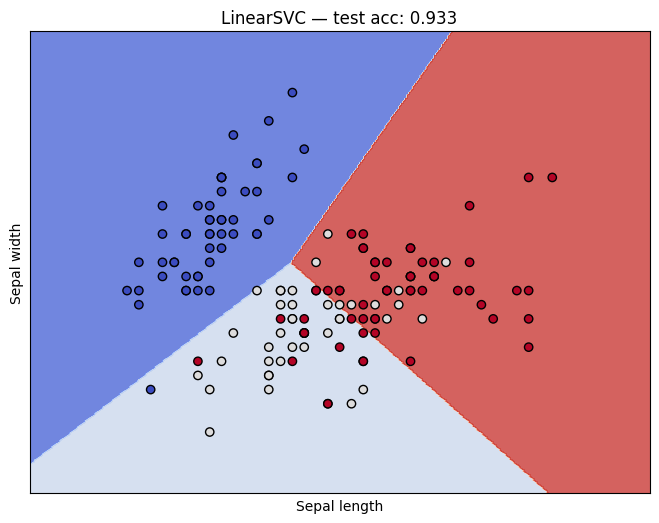

In [33]:
# Train a LinearSVC — a fast, linear-kernel support vector classifier.
# How an SVM works: it finds the hyperplane that separates the classes while
# maximising the margin (the gap between the nearest points of each class and
# the boundary). Points that lie on or inside the margin are the "support
# vectors" — only they define the boundary; all other points are irrelevant.
# This makes SVMs memory-efficient and resistant to outliers that are far from
# the boundary.
# Why LinearSVC instead of SVC(kernel='linear'): LinearSVC uses a more efficient
# solver (liblinear) that scales better to large datasets. SVC uses libsvm, which
# computes the full kernel matrix and becomes slow as n grows. For purely linear
# boundaries the two are equivalent in theory.
# Why penalty='l2' and loss='squared_hinge': these are the default SVM
# regularisation and loss settings. L2 penalty shrinks the weight vector,
# preventing overfitting. Squared hinge loss is slightly smoother than standard
# hinge loss and converges faster with liblinear's solver.
# Why max_iter=1e5: the default iteration limit is sometimes too low for
# convergence on some datasets; increasing it avoids ConvergenceWarnings.
clf = sk.svm.LinearSVC(penalty='l2', loss='squared_hinge', random_state=0, max_iter=int(10e4))
clf.fit(X_train, y_train)

train_acc = clf.score(X_train, y_train)
test_acc  = clf.score(X_test,  y_test)
print(f"Training accuracy: {train_acc:.3f}")
print(f"Testing  accuracy: {test_acc:.3f}")

# A gap between training and test accuracy indicates overfitting.
# A low training accuracy indicates underfitting (model is too simple).
plt.figure(figsize=(8, 6))
plot_fit(X_scaled, y, clf)
plt.title(f'LinearSVC — test acc: {test_acc:.3f}')
plt.show()

## Exercise 1) Kernel
Try other kernels than linear: `linear`, `rbf`, and `poly`.

Linear SVC: train=0.767  test=0.933
Linear kernel: train=0.775  test=0.900
RBF kernel: train=0.775  test=0.900


/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kornelkowalczyk/dev/2024/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Poly kernel: train=0.742  test=0.633


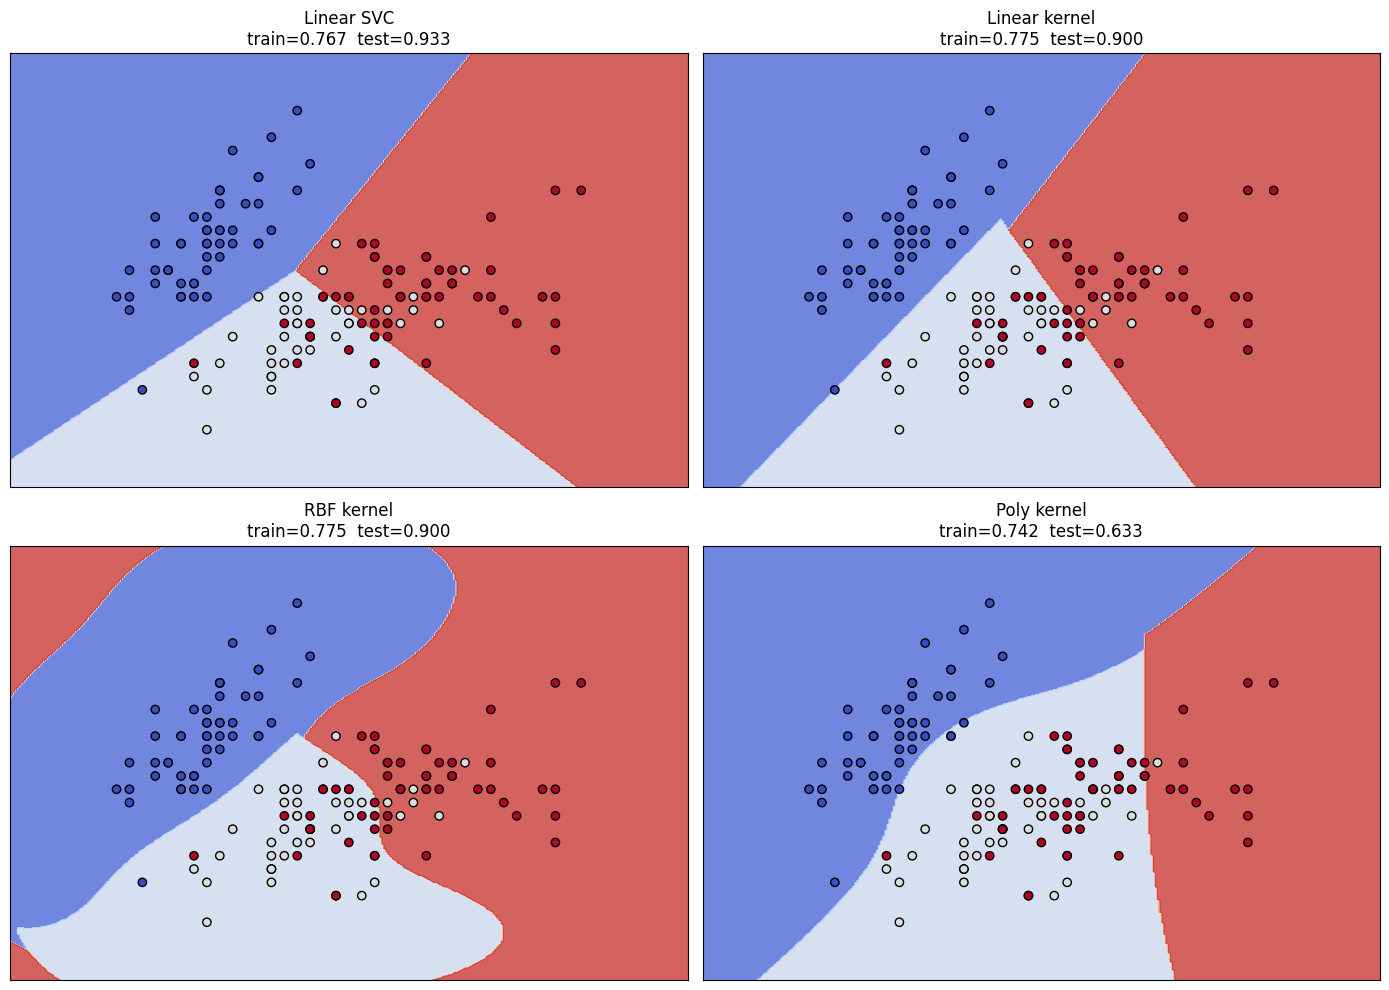

In [34]:
# Exercise 1: compare four kernel types to understand the effect of the kernel.
# The "kernel trick" is the key insight of SVMs: instead of explicitly mapping
# the data into a high-dimensional feature space, the kernel function computes
# dot products in that space implicitly, which is far cheaper.
#
# Linear kernel: finds a straight hyperplane boundary. Fastest to train and most
#   interpretable, but cannot separate classes that are not linearly separable.
#   Equivalent to LinearSVC above.
#
# RBF (Radial Basis Function) kernel: k(x,z) = exp(-γ‖x-z‖²). Each support
#   vector acts like a "bump" — points close to a support vector get a high
#   similarity score; far-away points get a score near zero. The resulting
#   boundary can be arbitrarily curved, which handles non-linear separation well.
#   γ controls the width of each bump: large γ → narrow bumps → jagged boundary
#   (risk of overfitting); small γ → smooth, gentle boundary.
#
# Polynomial kernel: k(x,z) = (x·z + 1)^d. Effectively fits a degree-d
#   polynomial boundary. Degree=3 (cubic) is a common default — flexible enough
#   for most tasks while still being interpretable geometrically.
#
# C (regularisation): present in all kernels. Large C → hard margin (tries to
#   classify every training point correctly, risks overfitting). Small C → soft
#   margin (allows some misclassifications for a smoother, more generalisable boundary).
C      = 1.0  # Regularisation strength — trades off margin size vs. training errors
gamma  = 0.7  # RBF kernel bandwidth — controls how localised each support vector's influence is
degree = 3    # Polynomial kernel degree

classifiers = {
    'Linear SVC':    sk.svm.LinearSVC(C=C, max_iter=int(10e4), random_state=0),
    'Linear kernel': sk.svm.SVC(kernel='linear', C=C),
    'RBF kernel':    sk.svm.SVC(kernel='rbf',  gamma=gamma, C=C),
    'Poly kernel':   sk.svm.SVC(kernel='poly', degree=degree, C=C),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, (name, model) in zip(axes, classifiers.items()):
    model.fit(X_train, y_train)
    train_a = model.score(X_train, y_train)
    test_a  = model.score(X_test,  y_test)
    print(f"{name}: train={train_a:.3f}  test={test_a:.3f}")

    # Re-draw the decision boundary directly onto the subplot axes
    # (plot_fit uses pyplot state so we reproduce it manually here)
    h = .02
    x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
    y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='black')
    ax.set_title(f'{name}\ntrain={train_a:.3f}  test={test_a:.3f}')
    ax.set_xticks(())
    ax.set_yticks(())

plt.tight_layout()
plt.show()

## Exercise 2) More dimensions
Use 3 features (sepal length, sepal width, petal length) and visualise the predictions in 3D.

3-feature RBF SVM: train=0.967  test=0.933
Compare with the 2-feature results above — the extra feature should improve accuracy.


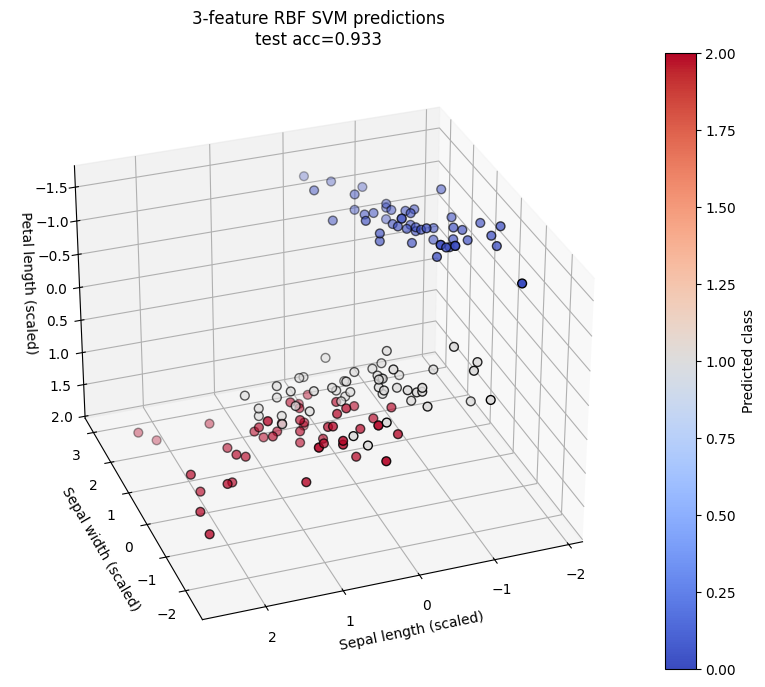

In [35]:
# Exercise 2: add a third feature (petal length) and visualise predictions in 3D.
# Why adding more features can help: the two sepal features alone leave the
# versicolor and virginica classes heavily overlapping (as the plots above show).
# Petal length carries very different information — it correlates strongly with
# species and divides the classes in a direction that the sepal plane cannot.
# This is the "curse of dimensionality" in reverse: more relevant features give
# the SVM more axes along which to place its separating hyperplane.
# Why we can no longer plot a 2D decision boundary: the SVM now lives in 3D
# feature space. The boundary is a 2D surface (a plane for linear kernel, a
# curved surface for RBF/poly) embedded in that 3D space. We cannot render this
# surface directly without projecting back down to 2D, which would be misleading.
# Instead we plot every data point in 3D, coloured by its predicted class.
# This gives intuition about where the classes cluster in the 3D feature space
# even though the boundary surface itself is not rendered.
X3 = iris_df.iloc[:, :3].values  # Sepal length, sepal width, petal length
X3_scaled = StandardScaler().fit_transform(X3)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3_scaled, y, test_size=0.2, random_state=42
)

# RBF chosen here because it showed competitive 2D performance and handles
# non-linear separation that the added petal-length axis benefits from.
clf3 = sk.svm.SVC(kernel='rbf', gamma=gamma, C=C)
clf3.fit(X3_train, y3_train)

train_a3 = clf3.score(X3_train, y3_train)
test_a3  = clf3.score(X3_test,  y3_test)
print(f"3-feature RBF SVM: train={train_a3:.3f}  test={test_a3:.3f}")
print("Compare with the 2-feature results above — the extra feature should improve accuracy.")

# Predict labels for all 150 samples so we can colour the 3D scatter by
# predicted class (not ground truth), which shows what the model "believes".
y_pred3 = clf3.predict(X3_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.view_init(elev=-150, azim=110)   # elev/azim chosen to separate the three clusters visually
scatter = ax.scatter(
    X3_scaled[:, 0], X3_scaled[:, 1], X3_scaled[:, 2],
    c=y_pred3, cmap=plt.cm.coolwarm, edgecolors='black', s=40
)
ax.set_xlabel('Sepal length (scaled)')
ax.set_ylabel('Sepal width (scaled)')
ax.set_zlabel('Petal length (scaled)')
ax.set_title(f'3-feature RBF SVM predictions\ntest acc={test_a3:.3f}')
plt.colorbar(scatter, ax=ax, label='Predicted class')
plt.show()

## Exercise 3) Even more dimensions
Use all 4 features.

In [36]:
# Exercise 3: use all 4 features and compare all kernels.
# Why all 4 features: each additional relevant feature gives the SVM another
# dimension in which to look for a separating surface. Petal width (the 4th
# feature) independently distinguishes setosa from the other two species, so
# adding it provides complementary information to what the first three features
# already captured. In practice, adding redundant or noisy features can actually
# hurt accuracy (they add variance without signal), but for the Iris dataset all
# four features are informative, so accuracy generally improves.
# Why no 3D/4D visualisation here: there is no intuitive way to visualise a
# 4D point cloud or a 3D decision surface. The accuracy numbers are the primary
# result; one could project to 2D using PCA for visualisation (see Exercise 2 notebook).
X4 = iris_df.values  # All four features
X4_scaled = StandardScaler().fit_transform(X4)

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4_scaled, y, test_size=0.2, random_state=42
)

results = {}
for name, model in [
    ('LinearSVC',  sk.svm.LinearSVC(C=C, max_iter=int(10e4), random_state=0)),
    ('SVC linear', sk.svm.SVC(kernel='linear', C=C)),
    ('SVC rbf',    sk.svm.SVC(kernel='rbf', gamma=gamma, C=C)),
    ('SVC poly',   sk.svm.SVC(kernel='poly', degree=degree, C=C)),
]:
    model.fit(X4_train, y4_train)
    ta = model.score(X4_train, y4_train)
    va = model.score(X4_test,  y4_test)
    results[name] = (ta, va)
    print(f"{name:20s}: train={ta:.3f}  test={va:.3f}")

# Summary: compare directly with the 2- and 3-feature results to see
# how each extra feature contributes to classification performance.
# High test accuracy with low training accuracy = underfitting (model too simple).
# Test accuracy lower than training accuracy = overfitting (model too complex).
# The ideal is training ≈ test, both high.
print("\nSummary (4 features):")
for name, (ta, va) in results.items():
    print(f"  {name:20s} train={ta:.3f}  test={va:.3f}")

LinearSVC           : train=0.950  test=1.000
SVC linear          : train=0.983  test=0.967
SVC rbf             : train=0.975  test=1.000
SVC poly            : train=0.933  test=0.967

Summary (4 features):
  LinearSVC            train=0.950  test=1.000
  SVC linear           train=0.983  test=0.967
  SVC rbf              train=0.975  test=1.000
  SVC poly             train=0.933  test=0.967
